# **ANÁLISIS DE POSICIONAMIENTO EN YOUTUBE**


## 1. Contexto

El posicionamiento en plataformas como YouTube representa una oportunidad para entender las preferencias de la audiencia y encontrar patrones de consumo. El objetivo es analizar los videos que fueron tendencia en Estados Unidos, con el fin de identificar patrones asociados con su popularidad, la interacción de los usuarios, el comportamiento, las diferencias entre categorías y las visualizaciones.

A partir de un análisis exploratorio y mediante la aplicación de la ciencia de datos, el propósito es encontrar información que permita entender mejor el comportamiento de los videos en tendencia y, con ello, tomar decisiones.

### Objetivos específicos

* Identificar las categorías y los canales con mayor presencia en Trending.
* Analizar el comportamiento de las visualizaciones y las interacciones de los usuarios.
* Estudiar cuánto tiempo transcurre entre la publicación de un video y su primera aparición en Trending.
* Identificar patrones de comportamiento entre diferentes tipos de contenido.
* Evaluar la posibilidad de desarrollar modelos que permitan caracterizar o estimar el comportamiento de los videos.

## 2. Importación de datos

In [17]:
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().parent
sys.path.insert(0, str(ROOT_DIR))

from utils.kaggle_utils import import_data

us_videos = import_data('USvideos.csv')
us_category_id = import_data('US_category_id.json')


## 3. Analisís Inicial

In [18]:
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")

print("USvideos size:", us_videos.shape)
print("USvideos size unique rows:", us_videos.drop_duplicates(inplace=False).shape)
print("US_category_id size:", us_category_id.shape)
print("_____________________________________________________________")
print("USvideos columns:", us_videos.columns.tolist())
print("US_category_id columns:", us_category_id.columns.tolist())
print("_____________________________________________________________")
display(us_videos.head())
display(us_category_id.head())
print("_____________________________________________________________")
us_videos.info()
us_category_id.info()
print("_____________________________________________________________")
us_videos.drop_duplicates(inplace=False).isnull().sum()



USvideos size: (40949, 16)
USvideos size unique rows: (40901, 16)
US_category_id size: (32, 3)
_____________________________________________________________
USvideos columns: ['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description']
US_category_id columns: ['kind', 'etag', 'items']
_____________________________________________________________


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...
1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13T07:30:00.000Z,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John..."
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...
3,puqaWrEC7tY,17.14.11,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13T11:00:04.000Z,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...
4,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...


,kind,etag,items
0,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
1,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
2,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
3,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
4,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."


_____________________________________________________________
<class 'pandas.DataFrame'>
RangeIndex: 40949 entries, 0 to 40948
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   video_id                40949 non-null  str  
 1   trending_date           40949 non-null  str  
 2   title                   40949 non-null  str  
 3   channel_title           40949 non-null  str  
 4   category_id             40949 non-null  int64
 5   publish_time            40949 non-null  str  
 6   tags                    40949 non-null  str  
 7   views                   40949 non-null  int64
 8   likes                   40949 non-null  int64
 9   dislikes                40949 non-null  int64
 10  comment_count           40949 non-null  int64
 11  thumbnail_link          40949 non-null  str  
 12  comments_disabled       40949 non-null  bool 
 13  ratings_disabled        40949 non-null  bool 
 14  video_error_or_remo

video_id                    0
trending_date               0
title                       0
channel_title               0
category_id                 0
publish_time                0
tags                        0
views                       0
likes                       0
dislikes                    0
comment_count               0
thumbnail_link              0
comments_disabled           0
ratings_disabled            0
video_error_or_removed      0
description               569
dtype: int64

In [19]:
us_category_id.isnull().sum()

kind     0
etag     0
items    0
dtype: int64

En el análisis inicial se revisó la información de cada tabla:

**USvideos.csv:** Contiene 16 columnas y 40.949 registros, aunque hay 48 duplicados en todas sus columnas, por lo que la cantidad final de filas es 40.901. Esta tabla contiene datos como `video_id`, `trending_date`, `title`, `channel_title`, `category_id`, `publish_time`, `tags`, `views`, `likes`, `dislikes`, `comment_count`, `thumbnail_link`, `comments_disabled`, `ratings_disabled`, `video_error_or_removed` y `description`, cuyos nombres son bastante dicientes sobre los datos que los componen. Los tipos de datos deben ser casteados para su correcto uso y solo se encontraron 570 valores nulos en la columna `description`.

**US_category_id.json:** Contiene el catálogo de categorías de YouTube en formato JSON. Incluye información como el identificador de cada categoría (`id`), su nombre (`title`) y un atributo que indica si la categoría puede asignarse (`assignable`). Esta información permite interpretar los valores de `category_id` presentes en los registros de videos y facilitar su clasificación y análisis por categoría.

Para el análisis de los datos se utilizará PostgreSQL, ya que facilita las consultas y la transformación de datos, particularmente en las funciones de agregación, operaciones con fechas y análisis temporal. Además se parseara el json de la tabla US_category_id antes de cargarla en la base de datos.

In [20]:
import pandas as pd
from utils.postgres_utils import write_to_postgres, read_from_postgres, execute_query

us_category_id_parsed = pd.json_normalize(
    us_category_id["items"].tolist(),
    sep="_",
).rename(columns={
    "snippet_title": "title",
    "snippet_assignable": "assignable",
})[["id", "title", "assignable"]]
us_category_id_parsed["id"] = us_category_id_parsed["id"].astype("int64")

us_videos_to_load = us_videos.drop_duplicates().copy()
us_videos_to_load["trending_date"] = pd.to_datetime(
    us_videos_to_load["trending_date"], format="%y.%d.%m"
).dt.date
us_videos_to_load["publish_time"] = pd.to_datetime(
    us_videos_to_load["publish_time"], utc=True
).dt.tz_localize(None)


#write_to_postgres("us_videos", us_videos_to_load)
#write_to_postgres("us_category_id", us_category_id_parsed)

## 4. Limpieza y validación 

### 4.1 Consolidación de video y fechas de tendencia

In [21]:
path_duplicate_video_dates = './queries/01_identify_duplicate_video_dates.sql'
duplicate_video_dates = read_from_postgres(ROOT_DIR / path_duplicate_video_dates)
print("Videos con incositencias en la data")
display(duplicate_video_dates)
path_us_video_daily = './queries/02_consolidate_video_date_records.sql'
us_videos_daily = read_from_postgres(ROOT_DIR / path_us_video_daily)
execute_query("TRUNCATE test.us_videos_daily;")
write_to_postgres("us_videos_daily", us_videos_daily)
path_video_date_granularity = './queries/03_validate_video_date_granularity.sql'
video_date_granularity = read_from_postgres(ROOT_DIR / path_video_date_granularity)
display(video_date_granularity)


Videos con incositencias en la data


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,tipo_error
0,kZete48ZtsY,2018-01-29,Roger Federer 20th Grand Slam Victory Tribute,ATPWorldTour,17,2018-01-28 17:47:53,[none],33042,1297,12,96,https://i.ytimg.com/vi/kZete48ZtsY/default.jpg,f,f,f,Watch this tribute looking back at Roger Feder...,Inconsistencia en fecha de publicación
1,kZete48ZtsY,2018-01-30,Roger Federer 20th Grand Slam Victory Tribute,ATPWorldTour,17,2018-01-28 17:47:53,[none],64330,1829,21,145,https://i.ytimg.com/vi/kZete48ZtsY/default.jpg,f,f,f,Watch this tribute looking back at Roger Feder...,Inconsistencia en fecha de publicación
2,kZete48ZtsY,2018-01-31,Roger Federer's 20th Grand Slam Victory Tribute,ATPWorldTour,17,2018-01-28 17:47:53,"atp|""world""|""tour""|""2018""|""tennis""|""sport""|""pr...",74080,1977,22,162,https://i.ytimg.com/vi/kZete48ZtsY/default.jpg,f,f,f,Watch this tribute looking back at Roger Feder...,Inconsistencia en fecha de publicación
3,kZete48ZtsY,2018-02-01,Deleted video,Midnight Video,1,2018-01-29 13:00:00,"horror|""horror short""|""short""|""short film""|""my...",60262,4804,122,736,https://i.ytimg.com/vi/-V1Oo7srGf0/default.jpg,f,f,t,After dusting off an old Mystery Date-style bo...,Inconsistencia en fecha de publicación
4,kZete48ZtsY,2018-02-02,Deleted video,DaHoopSpot Productions,17,2017-12-16 04:29:25,[none],2611,8,12,5,https://i.ytimg.com/vi/NzCSJrxQyQI/default.jpg,f,f,t,NaN,Inconsistencia en fecha de publicación
5,kZete48ZtsY,2018-02-03,Deleted video,DaHoopSpot Productions,17,2017-12-16 04:29:25,[none],2620,8,12,5,https://i.ytimg.com/vi/NzCSJrxQyQI/default.jpg,f,f,t,NaN,Inconsistencia en fecha de publicación
6,ogfYd705cRs,2018-05-09,Google I/O'18: Google Keynote,Google Developers,28,2018-04-24 22:03:35,"Google I/O 2018 keynote|""Google I/O 2018 lives...",853051,17455,1567,0,https://i.ytimg.com/vi/ogfYd705cRs/default_liv...,t,f,f,Learn about the latest product and platform in...,Inconsistencia en fecha de publicación
7,ogfYd705cRs,2018-05-10,Keynote (Google I/O '18),Google Developers,28,2018-05-10 03:41:45,"Google I/O 2018 keynote|""Google I/O 2018 lives...",1375783,20953,2227,0,https://i.ytimg.com/vi/ogfYd705cRs/default.jpg,t,f,f,Learn about the latest product and platform in...,Inconsistencia en fecha de publicación
8,ogfYd705cRs,2018-05-11,Keynote (Google I/O '18),Google Developers,28,2018-05-10 03:41:45,"Google I/O 2018 keynote|""Google I/O 2018 lives...",2281355,25338,3004,0,https://i.ytimg.com/vi/ogfYd705cRs/default.jpg,t,f,f,Learn about the latest product and platform in...,Inconsistencia en fecha de publicación
9,ogfYd705cRs,2018-05-12,Keynote (Google I/O '18),Google Developers,28,2018-05-10 03:41:45,"Google I/O 2018 keynote|""Google I/O 2018 lives...",2920409,28293,3598,0,https://i.ytimg.com/vi/ogfYd705cRs/default.jpg,t,f,f,Learn about the latest product and platform in...,Inconsistencia en fecha de publicación


,tipo_error,video_id,detalle,valor


Se realizó una validación más detallada de los registros de videos en Trending, buscando casos en los que un mismo video_id y trending_date estuvieran asociados a diferentes valores en otras columnas.

Como resultado, se identificaron dos videos cuyos registros presentaban diferencias en las métricas de visualizaciones (`views`) y `likes`. Debido a que estas métricas son acumulativas, se decidió conservar los registros con los valores más altos y descartar los de menor valor, manteniendo así la observación con las métricas acumuladas más recientes para la fecha de Trending correspondiente.

### 4.2. Integridad de la categoría


In [22]:
path_category_integrity = './queries/04_validate_category_integrity.sql'
category_integrity = read_from_postgres(ROOT_DIR / path_category_integrity)
display(category_integrity)

,category_id,affected_records,non_assignable_records
0,1,0,0
1,2,0,0
2,10,0,0
3,15,0,0
4,17,0,0
5,19,0,0
6,20,0,0
7,22,0,0
8,23,0,0
9,24,0,0


Se verificó que todos los valores de `category_id` de los videos tuvieran correspondencia con un `id` existente en el catálogo de categorías, lo cual se cumple para todos los registros.

Adicionalmente, se identificó que existen categorías con el atributo `assignable = FALSE` que están asociadas a videos en Trending. Esta condición se tendrá en cuenta durante el análisis, ya que indica que dichas categorías no están habilitadas para asignarse a nuevos videos, aunque aparecen relacionadas con videos del dataset.

### 4.3 Consistencia en las fechas

In [23]:
path_date_consistency = './queries/05_validate_date_consistency.sql'
date_consistency = read_from_postgres(ROOT_DIR / path_date_consistency)
display(date_consistency)

,video_id,publish_time,trending_date


Se construyó us_videos_daily aplicando reglas generales que respetan la naturaleza de los datos:

* Detección de IDs corruptos (Regla del 3+2): Los canales se normalizan con LOWER() para evitar falsos positivos por mayúsculas, un `ID` se considera corrupto si tiene 3 o más canales distintos, o si tiene 2 canales con categorías distintas y un empate al 50%. Esto atrapa solo las mezclas reales y conserva los cambios de nombre legítimos.

* Corrección de canal y categoría (Moda): A los videos conservados se les asigna el channel_title y category_id más frecuente, unificando los cambios de nombre.

* Unificación de fecha de publicación (MIN): Para evitar días negativos en days_to_trending.

* Deduplicación diaria: Se conserva la fila con las métricas más altas por video_id + trending_date.

### 4.4 Validación de metricas negativas


In [24]:
path_negative_metrics = './queries/06_validate_negative_metrics.sql'
negative_metrics = read_from_postgres(ROOT_DIR / path_negative_metrics)
display(negative_metrics)

,negative_views,negative_likes,negative_dislikes,negative_comments
0,0,0,0,0


Se valida que las métricas numéricas de los videos no contengan valores negativos, específicamente las visualizaciones (`views`), los likes (`likes`), los dislikes (`dislikes`) y los comentarios (`comment_count`). Como resultado, no se encontraron valores negativos en ninguna de estas columnas, por lo que no se identificaron inconsistencias de este tipo en los registros.

### 4.5 Caracterización del dataset


In [25]:
path_summary_dataset = './queries/07_summary_dataset.sql'
summary_dataset = read_from_postgres(ROOT_DIR / path_summary_dataset)
display(summary_dataset)

,total_records,unique_videos,unique_channels,unique_categories,first_trending_date,last_trending_date,earliest_publish_datetime,latest_publish_datetime,records_comments_disabled,records_ratings_disabled,records_with_video_errors,total_views,total_likes,total_dislikes,total_comments
0,40893,6350,2198,16,2017-11-14,2018-06-14,2006-07-23,2018-06-14,632,169,20,12461403976,352957157,19479475,40968676


Una vez finalizado el proceso de limpieza y validación, se realizó una caracterización general del dataset para conocer su composición, cobertura temporal y volumen de interacciones.

El dataset final contiene **40.899 registros correspondientes a 6.351 videos únicos**, distribuidos entre 2.207 canales y 16 categorías. Esto significa que un mismo video puede tener múltiples observaciones, ya que se registra su información en cada fecha en la que aparece en Trending.

En cuanto a la cobertura temporal, los registros de Trending abarcan desde el 14 de noviembre de 2017 hasta el 14 de junio de 2018. Sin embargo, las fechas de publicación comprenden un período mucho más amplio, desde el 23 de julio de 2006 hasta el 14 de junio de 2018, por lo que también se incluyen videos publicados varios años antes de aparecer en Trending.

Respecto a las métricas de interacción, tomando la última observación disponible de cada video para evitar contabilizarlo repetidamente, se identificaron **12.461 millones de visualizaciones, 352,9 millones de likes, 19,4 millones de dislikes y 40,9 millones de comentarios**.

Finalmente, se identificaron 632 registros con comentarios deshabilitados y 169 con calificaciones deshabilitadas. No se encontraron registros marcados con errores de video o eliminación.

Esta caracterización permite establecer una visión general de la información disponible y sirve como punto de partida para el análisis exploratorio de los datos.

## 5. Análisis Exploratorio


### 5.1 Distribución de videos por categoría

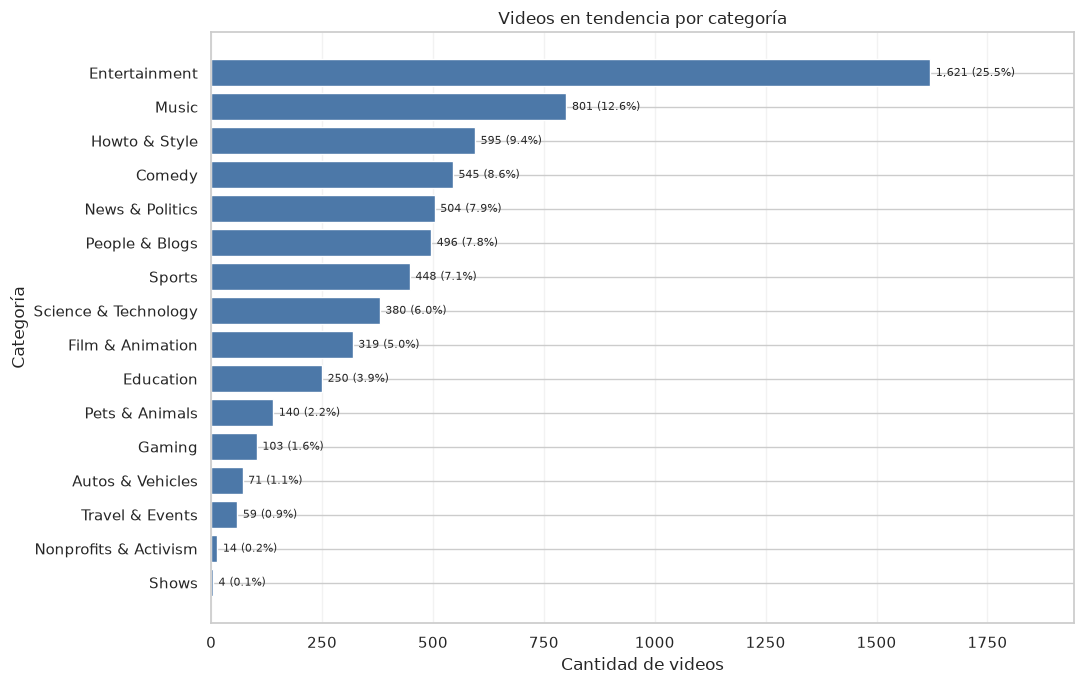

In [26]:
import matplotlib.pyplot as plt

path_distribution_by_category = './queries/08_video_distribution_by_category.sql'
distribution_by_category = read_from_postgres(ROOT_DIR / path_distribution_by_category)

plot_data = distribution_by_category.sort_values("total_videos", ascending=True)
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_data["category"], plot_data["total_videos"], color="#4C78A8")
labels = [
    f"{count:,} ({percentage:.1f}%)"
    for count, percentage in zip(
        plot_data["total_videos"], plot_data["percentage"]
    )
]
ax.bar_label(bars, labels=labels, padding=4, fontsize=8)
ax.set_title("Videos en tendencia por categoría")
ax.set_xlabel("Cantidad de videos")
ax.set_ylabel("Categoría")
ax.set_xlim(0, plot_data["total_videos"].max() * 1.2)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

Se analizó la distribución de los 6.351 videos únicos entre las 16 categorías presentes en el dataset. Se encontró que **Entertainment** concentra la mayor cantidad de videos, con 1.621 registros (25,5 %), seguida de **Music**, con 801 (12,6 %). Estas dos categorías representan aproximadamente el 38,1 % del total. También se observa que la distribución disminuye considerablemente en las categorías con menor representación. Por ejemplo, **Nonprofits & Activism** cuenta con 14 videos y **Shows** con tan solo 4.

Esto evidencia que existe una concentración de videos en determinadas categorías y una representación mucho menor en otras. Esta diferencia deberá tenerse en cuenta al realizar comparaciones y análisis posteriores, especialmente en aquellas categorías con pocos registros.

### 5.2 Distribución de videos en tendencia por canal

Se muestran los 20 canales con más videos únicos en tendencia. El porcentaje de cada canal se calcula sobre el total de videos únicos, no solo sobre los canales incluidos en el gráfico.

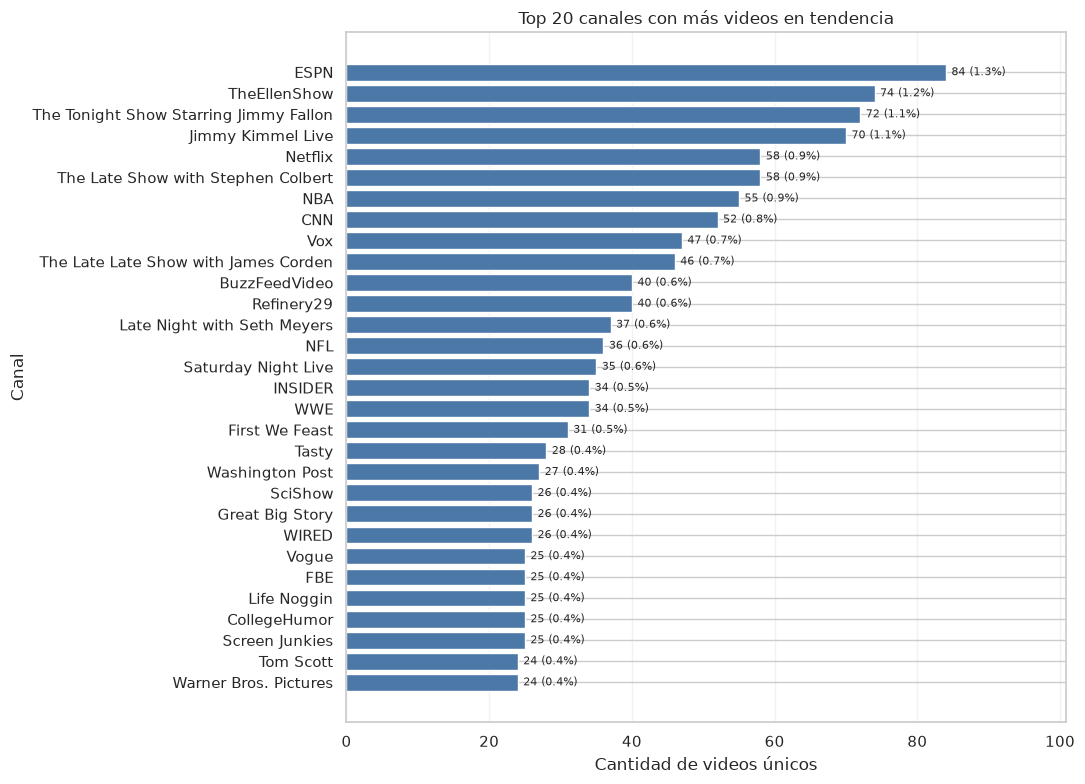

In [27]:
path_distribution_by_channel = './queries/09_video_distribution_by_channel.sql'
distribution_by_channel = read_from_postgres(ROOT_DIR / path_distribution_by_channel)

plot_channel_data = (
    distribution_by_channel.sort_values("total_videos", ascending=True)
)
fig, ax = plt.subplots(figsize=(11, 8))
bars = ax.barh(
    plot_channel_data["channel_title"],
    plot_channel_data["total_videos"],
    color="#4C78A8",
)
labels = [
    f"{count:,} ({percentage:.1f}%)"
    for count, percentage in zip(
        plot_channel_data["total_videos"], plot_channel_data["percentage"]
    )
]
ax.bar_label(bars, labels=labels, padding=4, fontsize=8)
ax.set_title("Top 20 canales con más videos en tendencia")
ax.set_xlabel("Cantidad de videos únicos")
ax.set_ylabel("Canal")
ax.set_xlim(0, plot_channel_data["total_videos"].max() * 1.2)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### 5.3 Distribución de visualizaciones por video

count    6.350000e+03
mean     1.962426e+06
std      7.060570e+06
min      5.590000e+02
25%      1.591880e+05
50%      5.182330e+05
75%      1.473585e+06
90%      3.689416e+06
95%      6.719903e+06
99%      2.519013e+07
max      2.252119e+08
Name: views, dtype: float64

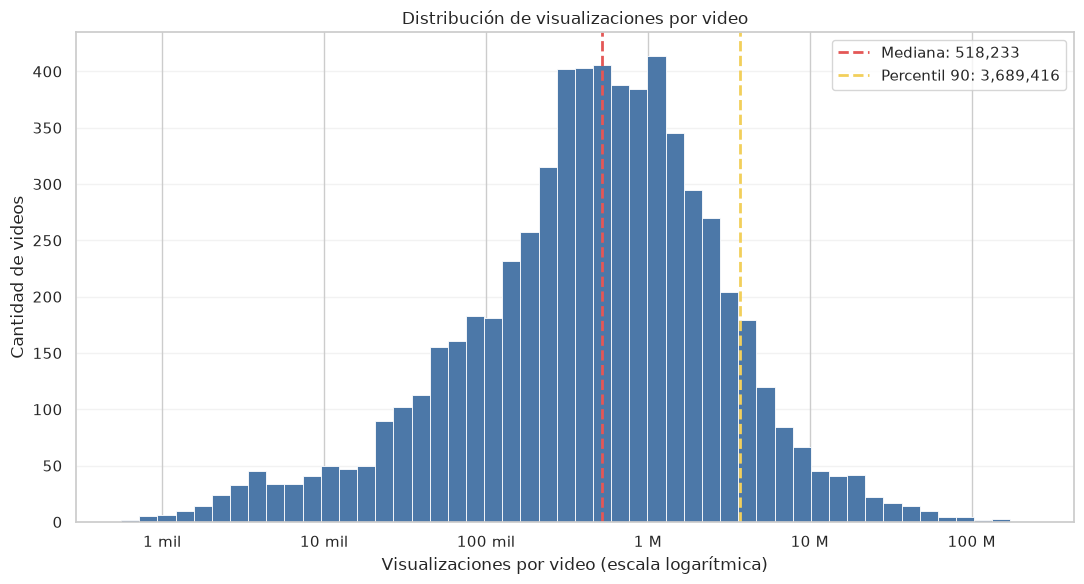

In [28]:
import numpy as np
from matplotlib.ticker import FuncFormatter

path_views_distribution = './queries/10_views_distribution.sql'
views_distribution = read_from_postgres(ROOT_DIR / path_views_distribution)
display(views_distribution["views"].describe(percentiles=[.25, .50, .75, .90, .95, .99]))
bins = np.geomspace(views_distribution['views'].min(), views_distribution['views'].max(), 51)

fig, ax = plt.subplots(figsize=(11, 6))
ax.hist(views_distribution['views'], bins=bins, color="#4C78A8", edgecolor="white", linewidth=0.6)
median_views = views_distribution['views'].median()
p90_views = views_distribution['views'].quantile(0.9)
ax.axvline(median_views, color="#E45756", linestyle="--", linewidth=2,
           label=f"Mediana: {median_views:,.0f}")
ax.axvline(p90_views, color="#F2CF5B", linestyle="--", linewidth=2,
           label=f"Percentil 90: {p90_views:,.0f}")
ax.set_xscale("log")

def format_views(value, _):
    if value >= 1_000_000:
        return f"{value / 1_000_000:g} M"
    if value >= 1_000:
        return f"{value / 1_000:g} mil"
    return f"{value:g}"

ax.xaxis.set_major_formatter(FuncFormatter(format_views))
ax.set_title("Distribución de visualizaciones por video")
ax.set_xlabel("Visualizaciones por video (escala logarítmica)")
ax.set_ylabel("Cantidad de videos")
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

En la distribución de visualizaciones del último corte registrado por video (`last_data`) se observa una fuerte asimetría positiva (cola derecha larga): la mediana se ubica en **518.107 visualizaciones**, mientras que el percentil 90 alcanza **3,69 millones** y el percentil 99 supera los **25,18 millones**.

Dado que `last_data` conserva únicamente la última observación disponible por `video_id`, las métricas reflejan el acumulado más reciente dentro de Trending (no la suma de días repetidos). Por esta razón, en el modelado posterior se aplicará transformación logarítmica (`log1p`) para estabilizar la varianza.

### 5.4 Rendimiento e interacción por categoría

,title_category,videos,median_views,median_likes,median_engagement_pct,median_like_ratio_pct,avg_days_trending
0,Entertainment,1621,606048.0,11733.0,2.25,96.00,6.14
1,Music,801,1096158.0,39940.0,3.81,97.74,8.08
2,Howto & Style,595,422918.0,15894.0,4.32,97.60,6.97
3,Comedy,545,788112.0,22884.0,3.41,96.82,6.34
4,News & Politics,504,178852.0,1174.5,1.39,83.57,4.93
5,People & Blogs,496,403951.0,13158.0,3.39,97.47,6.47
6,Sports,448,405785.0,4311.5,1.30,94.66,4.82
7,Science & Technology,380,431057.5,11272.0,2.89,96.49,6.30
8,Film & Animation,319,910966.0,12165.0,2.25,95.79,7.34
9,Education,250,364795.5,12534.5,3.74,97.10,6.61


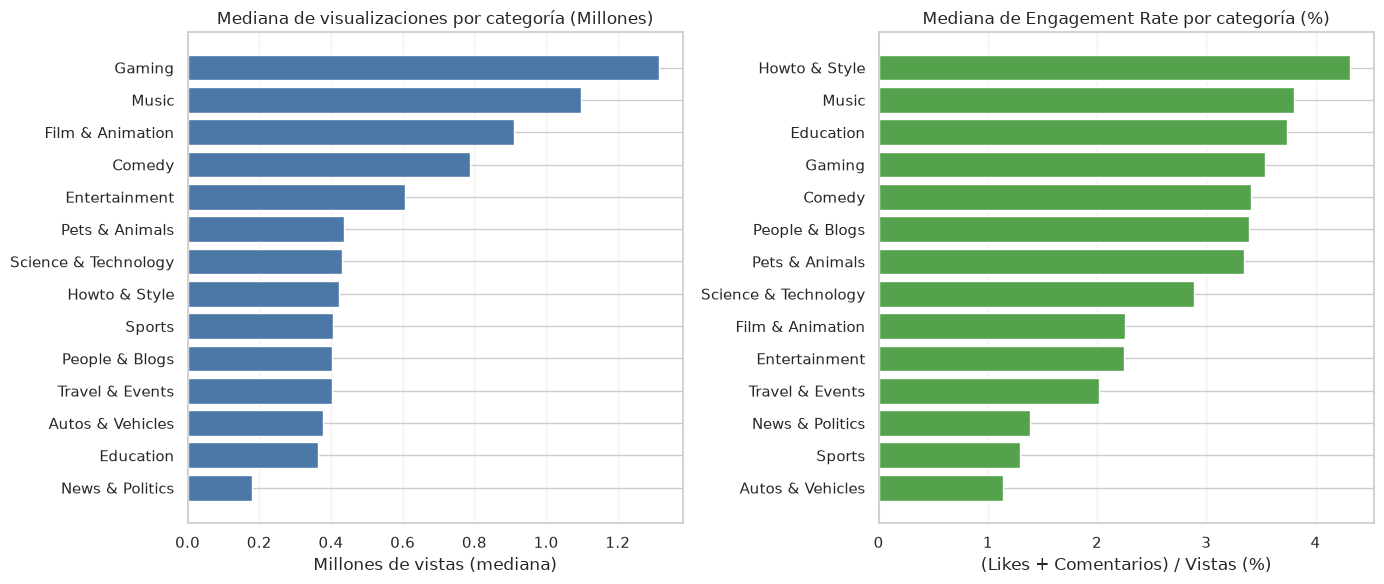

In [29]:
import seaborn as sns

path_category_engagement = './queries/11_category_engagement_summary.sql'
category_engagement = read_from_postgres(ROOT_DIR / path_category_engagement)

display(category_engagement.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

plot_views = category_engagement.sort_values("median_views", ascending=True)
axes[0].barh(plot_views["title_category"], plot_views["median_views"] / 1e6, color="#4C78A8")
axes[0].set_title("Mediana de visualizaciones por categoría (Millones)")
axes[0].set_xlabel("Millones de vistas (mediana)")
axes[0].grid(axis="x", alpha=0.25)

plot_eng = category_engagement.sort_values("median_engagement_pct", ascending=True)
axes[1].barh(plot_eng["title_category"], plot_eng["median_engagement_pct"], color="#54A24B")
axes[1].set_title("Mediana de Engagement Rate por categoría (%)")
axes[1].set_xlabel("(Likes + Comentarios) / Vistas (%)")
axes[1].grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()

### 5.5 Tiempo hasta Trending y estacionalidad


Distribución de días hasta llegar a Trending (percentiles):


count    6350.000000
mean       22.523937
std       209.979705
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
90%         4.000000
95%         6.000000
max      4215.000000
Name: days_to_trending, dtype: float64

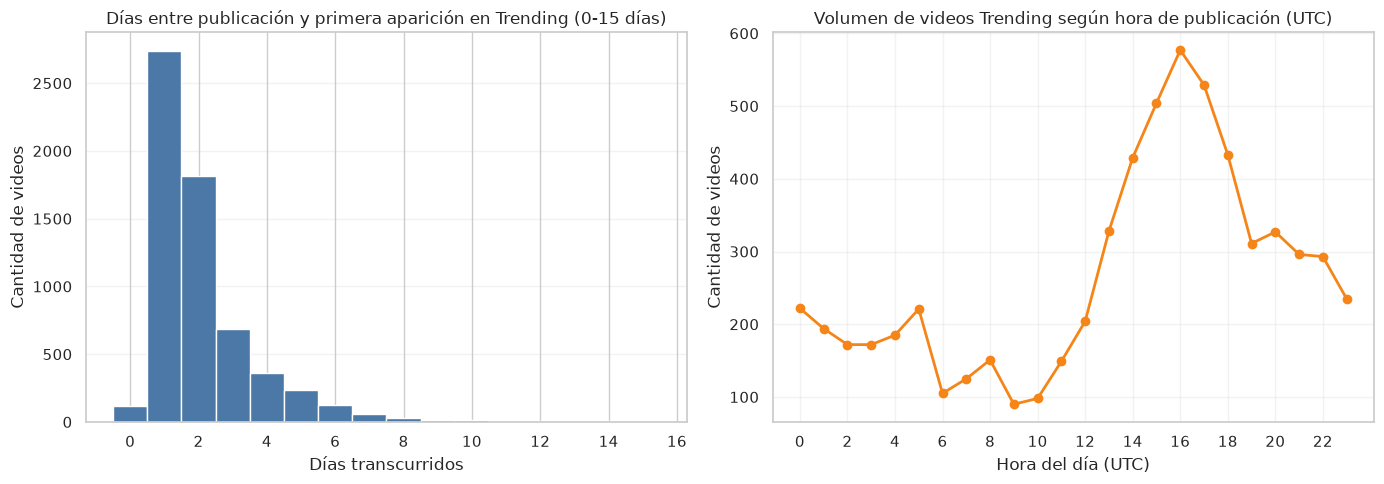

In [30]:

path_days_to_trending_and_publish_timing = './queries/12_days_to_trending_and_publish_timing.sql'
days_to_trending_and_publish_timing = read_from_postgres(ROOT_DIR / path_days_to_trending_and_publish_timing)
print("Distribución de días hasta llegar a Trending (percentiles):")
display(days_to_trending_and_publish_timing["days_to_trending"].describe(percentiles=[.25, .50, .75, .90, .95]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fast_trending = days_to_trending_and_publish_timing[days_to_trending_and_publish_timing["days_to_trending"] <= 15]["days_to_trending"]
axes[0].hist(fast_trending, bins=range(0, 17), align="left", color="#4C78A8", edgecolor="white")
axes[0].set_title("Días entre publicación y primera aparición en Trending (0-15 días)")
axes[0].set_xlabel("Días transcurridos")
axes[0].set_ylabel("Cantidad de videos")
axes[0].grid(axis="y", alpha=0.25)

hourly_counts = days_to_trending_and_publish_timing.groupby("publish_hour")["video_id"].count()
axes[1].plot(hourly_counts.index, hourly_counts.values, marker="o", color="#F58518", linewidth=2)
axes[1].set_title("Volumen de videos Trending según hora de publicación (UTC)")
axes[1].set_xlabel("Hora del día (UTC)")
axes[1].set_ylabel("Cantidad de videos")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, alpha=0.25)

fig.tight_layout()

### 5.6 Estacionalidad diaria y mensual

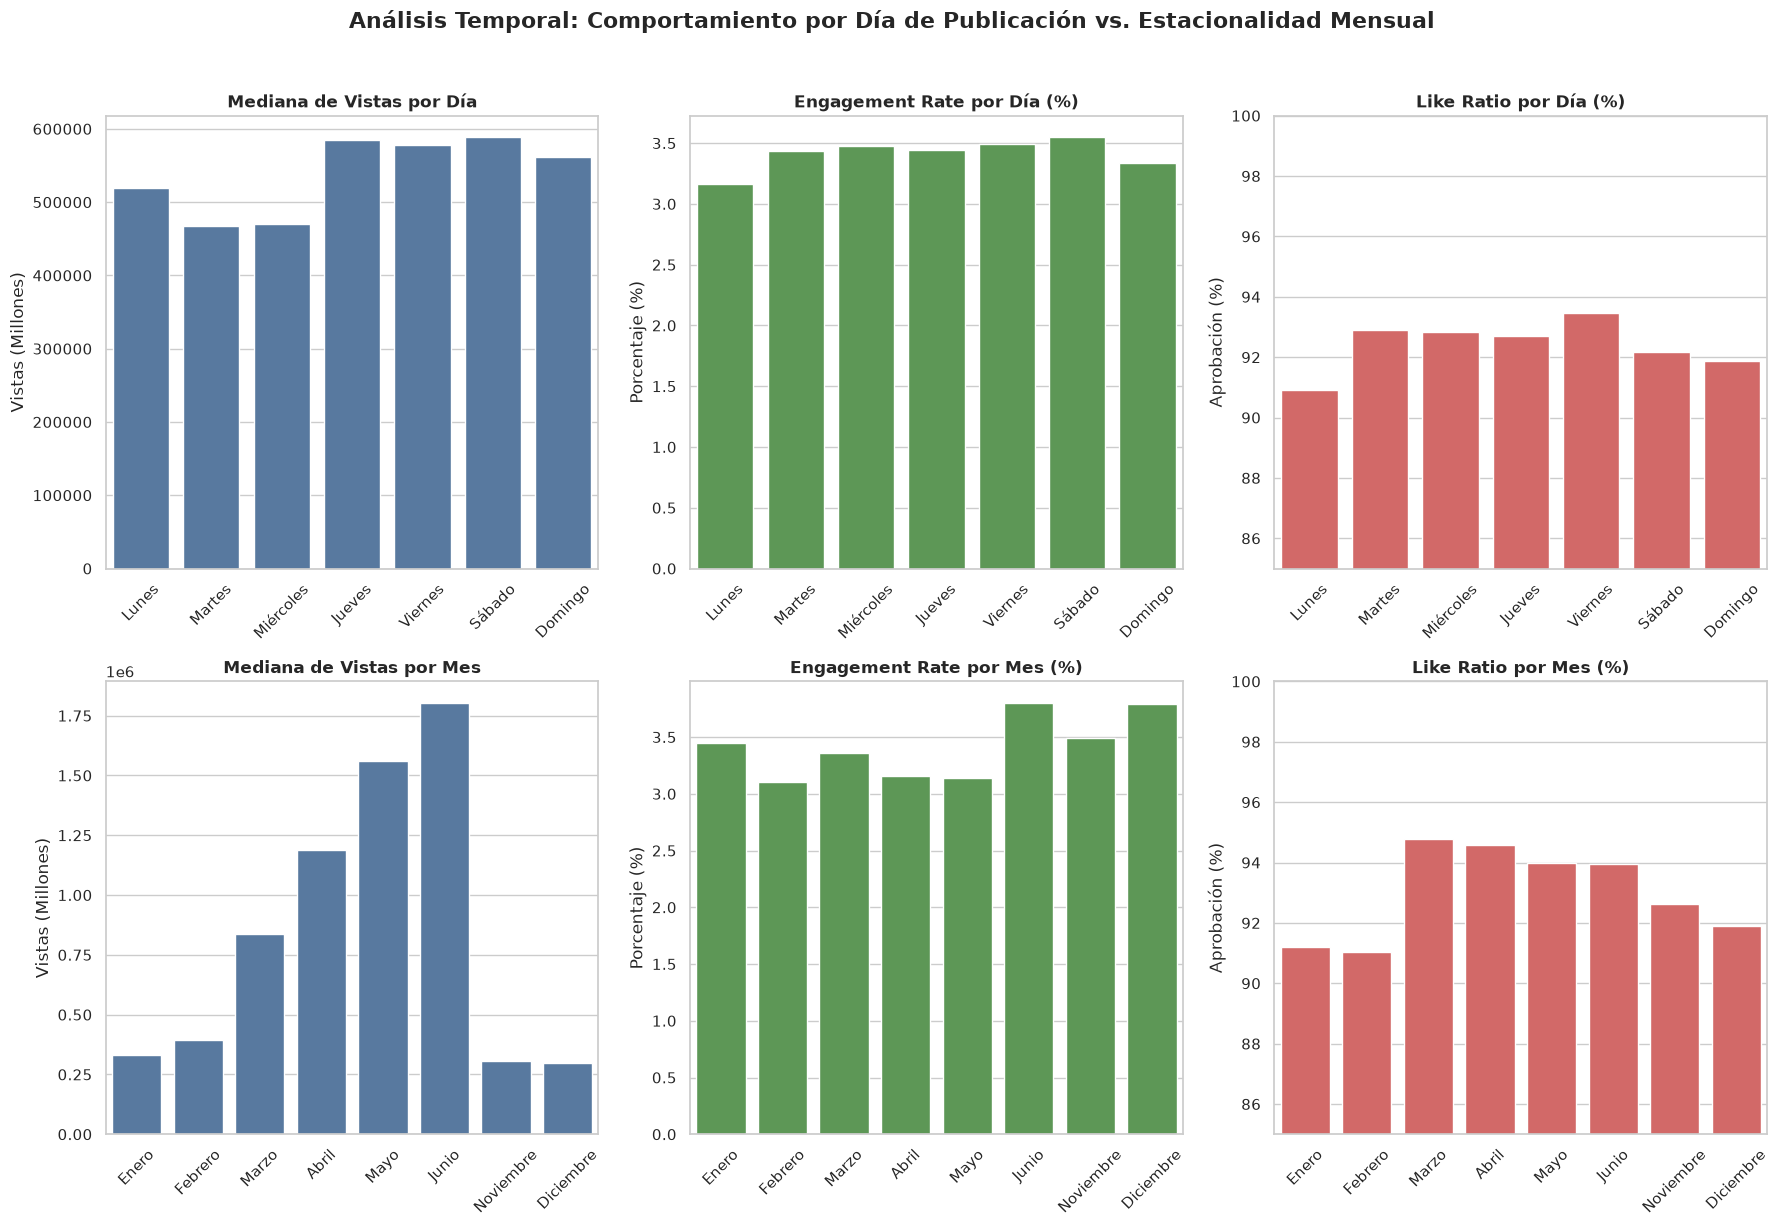

<Figure size 1000x500 with 0 Axes>

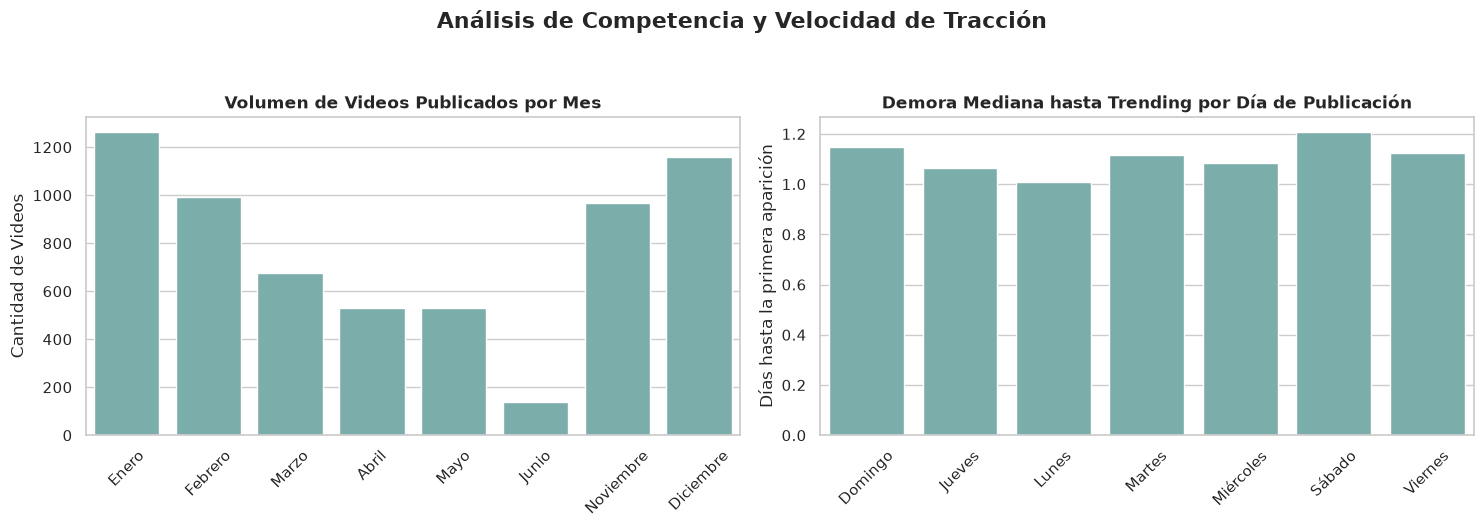

In [31]:
sns.set_theme(style="whitegrid", palette="muted")

path_daily = './queries/14_daily_engagement_like_ratio_seasonality.sql'
daily_data = read_from_postgres(ROOT_DIR / path_daily)

path_monthly = './queries/15_monthly_engagement_like_ratio_seasonality.sql'
monthly_data = read_from_postgres(ROOT_DIR / path_monthly)

path_timing_validation = './queries/13_timing_validation.sql'
timing_validation = read_from_postgres(ROOT_DIR / path_timing_validation)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

sns.barplot(data=daily_data, x="publish_weekday", y="median_views", ax=axes[0, 0], color="#4C78AB", errorbar=None)
axes[0, 0].set_title("Mediana de Vistas por Día", fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel("Vistas (Millones)")
axes[0, 0].set_xlabel("")
axes[0, 0].tick_params(axis="x", rotation=45)

sns.barplot(data=daily_data, x="publish_weekday", y="avg_engagement", ax=axes[0, 1], color="#54A24B", errorbar=None)
axes[0, 1].set_title("Engagement Rate por Día (%)", fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel("Porcentaje (%)")
axes[0, 1].set_xlabel("")
axes[0, 1].tick_params(axis="x", rotation=45)

sns.barplot(data=daily_data, x="publish_weekday", y="avg_like_ratio", ax=axes[0, 2], color="#E45756", errorbar=None)
axes[0, 2].set_title("Like Ratio por Día (%)", fontsize=12, fontweight='bold')
axes[0, 2].set_ylabel("Aprobación (%)")
axes[0, 2].set_xlabel("")
axes[0, 2].set_ylim(85, 100) # Zoom para ver diferencias
axes[0, 2].tick_params(axis="x", rotation=45)


sns.barplot(data=monthly_data, x="publish_month", y="median_views", ax=axes[1, 0], color="#4C78AB", errorbar=None)
axes[1, 0].set_title("Mediana de Vistas por Mes", fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel("Vistas (Millones)")
axes[1, 0].set_xlabel("")
axes[1, 0].tick_params(axis="x", rotation=45)

sns.barplot(data=monthly_data, x="publish_month", y="avg_engagement", ax=axes[1, 1], color="#54A24B", errorbar=None)
axes[1, 1].set_title("Engagement Rate por Mes (%)", fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel("Porcentaje (%)")
axes[1, 1].set_xlabel("")
axes[1, 1].tick_params(axis="x", rotation=45)

sns.barplot(data=monthly_data, x="publish_month", y="avg_like_ratio", ax=axes[1, 2], color="#E45756", errorbar=None)
axes[1, 2].set_title("Like Ratio por Mes (%)", fontsize=12, fontweight='bold')
axes[1, 2].set_ylabel("Aprobación (%)")
axes[1, 2].set_xlabel("")
axes[1, 2].set_ylim(85, 100) # Zoom para ver diferencias
axes[1, 2].tick_params(axis="x", rotation=45)

fig.suptitle("Análisis Temporal: Comportamiento por Día de Publicación vs. Estacionalidad Mensual", 
             fontsize=16, fontweight='bold', y=1.02)
fig.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid", palette="muted")

weekday_summary = (
    timing_validation.groupby("publish_weekday")
    .agg(videos=("video_id", "nunique"), median_days=("days_to_trending", "median"))
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=monthly_data, 
    x="publish_month", 
    y="total_videos", 
    ax=axes[0], 
    color="#72B7B2", 
    errorbar=None
)
axes[0].set_title("Volumen de Videos Publicados por Mes", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Cantidad de Videos")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(
    data=weekday_summary, 
    x="publish_weekday", 
    y="median_days", 
    ax=axes[1], 
    color="#72B7B2", 
    errorbar=None
)
axes[1].set_title("Demora Mediana hasta Trending por Día de Publicación", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Días hasta la primera aparición")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=45)

fig.suptitle("Análisis de Competencia y Velocidad de Tracción", fontsize=16, fontweight='bold', y=1.05)
fig.tight_layout()
plt.show()

>>Nota: Para evitar sesgos por ventanas de tiempo incompletas, este análisis solo considera videos publicados dentro del período del estudio (Noviembre 2017 - Junio 2018). Además, se aclara que el mes de Junio solo cuenta con 15 días de datos (el dataset termina el 14 de junio), por lo que sus métricas de volumen no son comparables 1:1 con meses completos.>>

El análisis cruzado de las fechas de publicación revela que el momento de publicación sí influye, pero el impacto depende del objetivo de la campaña:

1. Velocidad de tracción (Días hasta tendencia): El Lunes es el día más rápido (1.01 días / ~24 horas) y el Sábado el más lento (1.21 días / ~29 horas) para posicionar un video. Los fines de semana hay casi la mitad de videos en tendencia (547-558) en comparación con los días de semana (~1,000). Sin embargo, la tracción es más lenta, lo que sugiere una alta saturación de contenido en esos días.
Para un lanzamiento que requiera despegue inmediato lo más convenientes es publicar a inicio de semana (Lunes). Los fines de semana sufren de mayor competencia

2. Comportamiento por Día de la Semana (Consumo Pasivo vs Activo): El Domingo lidera la mediana de vistas (~861k), seguido del Jueves y Viernes.
El Miércoles tiene la tasa de engagement (~4.02%) y like ratio más altos, mientras que el Domingo y Lunes tienen la interacción más baja.
Los fines de semana hay un consumo pasivo (mucha gente viendo, poca interactuando). A mitad de semana, el consumo es activo (menos vistas, pero audiencia más conectada).

3. Estacionalidad (Meses): Existe una relación inversa. La primavera (Abril, Mayo, Junio) concentra las vistas más altas (1.1M - 1.6M) pero el engagement más bajo (~3.63%). El invierno (Nov, Dic, Ene) tiene menos vistas (~330k) pero el engagement y like ratio más altos (>4.0%). Como posibles causas de considera que en invierno compiten más de 1,000 videos al mes; en primavera, solo ~530. Menos competencia en primavera permite que los videos se vuelvan masivos.

Para campañas de Awareness / Vistas masivas se debe publicar en primavera (Abr-Jun) apuntando al Domingo (o Jueves/Viernes para capturar el pico del fin de semana).

Para campañas de Comunidad / Interacción se debería publicar en invierno (Nov-Ene) o los Miércoles.



## 7. Clustering



Videos únicos cargados: 6,350
Videos válidos para clustering: 6,319


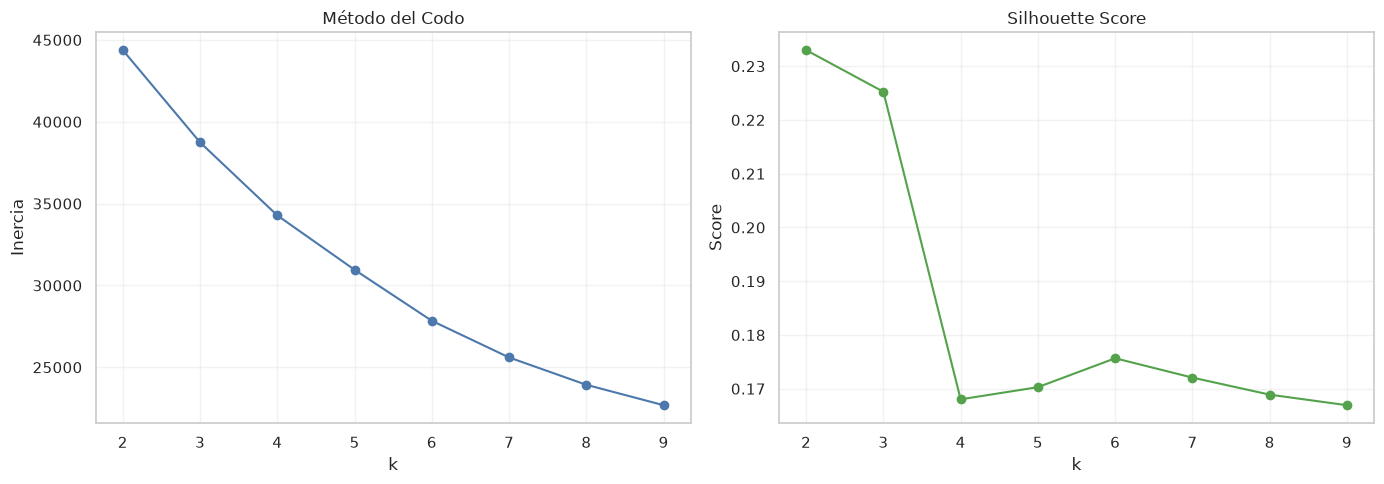

In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA


# 1. Cargar los datos desde la query SQL
path_video_level_for_clustering = './queries/16_video_level_for_clustering.sql'
video_level_for_clustering = read_from_postgres(ROOT_DIR / path_video_level_for_clustering)

# 2. Ingeniería de variables en Python
video_level_for_clustering["engagement_rate"] = (
    (video_level_for_clustering["likes"] + video_level_for_clustering["comment_count"]) / video_level_for_clustering["views"].replace(0, np.nan)
) * 100
video_level_for_clustering["like_ratio"] = (
    video_level_for_clustering["likes"] / (video_level_for_clustering["likes"] + video_level_for_clustering["dislikes"]).replace(0, np.nan)
) * 100
video_level_for_clustering["title_length"] = video_level_for_clustering["title"].str.len()
video_level_for_clustering["tags_count"] = video_level_for_clustering["tags"].apply(
    lambda x: len(str(x).split("|")) if pd.notna(x) and str(x) != "[none]" else 0
)
video_level_for_clustering["log_views"] = np.log1p(video_level_for_clustering["views"])
video_level_for_clustering["log_likes"] = np.log1p(video_level_for_clustering["likes"])
video_level_for_clustering["log_comments"] = np.log1p(video_level_for_clustering["comment_count"])

print(f"Videos únicos cargados: {len(video_level_for_clustering):,}")

# 3. Seleccionar features y eliminar nulos
features = [
    "log_views", "log_likes", "log_comments", "engagement_rate", 
    "like_ratio", "days_in_trending", "days_to_trending", 
    "title_length", "tags_count"
]
cluster_data = video_level_for_clustering[features].dropna().copy()
print(f"Videos válidos para clustering: {len(cluster_data):,}")

# 4. Escalar datos
scaler = StandardScaler()
scaled_data = scaler.fit_transform(cluster_data)

# 5. Método del Codo y Silhouette
inertias = []
silhouettes = []
K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(scaled_data)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(scaled_data, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(K_range, inertias, marker="o", color="#4C78AB")
axes[0].set_title("Método del Codo")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inercia")
axes[0].grid(alpha=0.25)

axes[1].plot(K_range, silhouettes, marker="o", color="#54A24B")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Score")
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()



Para determinar la segmentación óptima, se evaluaron los valores de k entre 2 y 9 utilizando el Método del Codo (Inercia) y el Silhouette Score. A partir de las gráficas, se identificaron tres candidatos clave que representan diferentes enfoques:

* k = 2 (El óptimo matemático): Presenta el Silhouette Score más alto (~0.233). Esto indica que la separación entre dos grupos es la más nítida y definida estadísticamente.

* k = 4 (El punto de estabilización): En el Método del Codo, la inercia comienza a aplanarse a partir de este punto. En el Silhouette Score, aunque el valor cae, es el punto donde la métrica deja de descender bruscamente y comienza a estabilizarse.

* k = 6 (El óptimo local): En la gráfica de Silhouette se observa un pico local claro (~0.175) que rompe la tendencia a la baja, indicando que seis grupos tienen una estructura interna mejor definida que cinco o siete.

Los tres valores representan escenarios válidos: k=2 por pureza matemática, k=4 por equilibrio y estabilidad, y k=6 por granularidad local. El paso siguiente es evaluar cuál de estos tres escenarios ofrece el mejor balance entre separación visual (PCA) y utilidad estratégica para el negocio.

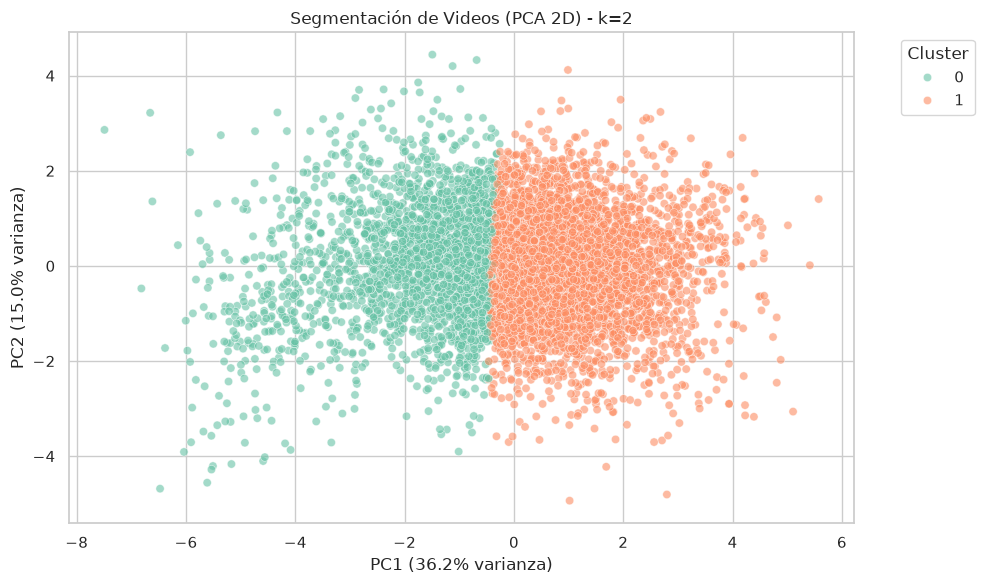

,videos,median_views,median_likes,avg_engagement,avg_like_ratio,avg_days_in_trending,avg_days_to_trending,avg_tags
cluster,,,,,,,,
0,2282,97988.0,1516.5,2.17,87.47,3.91,57.95,17.58
1,4037,1045168.0,26668.0,4.07,95.28,7.88,1.57,21.30


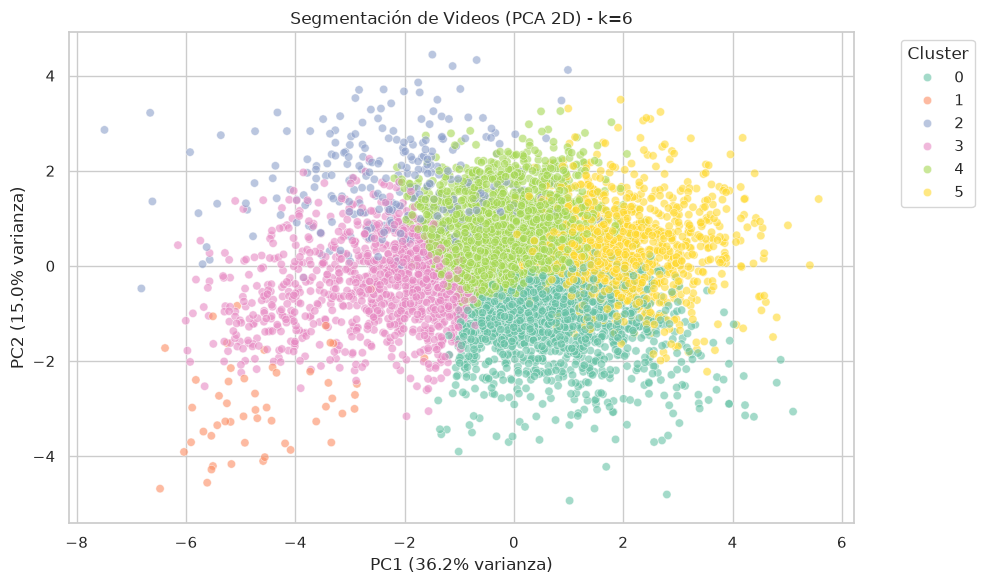

,videos,median_views,median_likes,avg_engagement,avg_like_ratio,avg_days_in_trending,avg_days_to_trending,avg_tags
cluster,,,,,,,,
0,1561,485881.0,22479.0,6.27,97.19,5.60,2.13,16.45
1,52,26536.5,80.5,0.60,91.66,3.38,2176.58,10.25
2,317,180919.0,1012.0,1.51,52.38,5.02,7.21,14.58
3,993,38447.0,491.0,1.95,91.80,3.68,15.14,14.04
4,2123,538169.0,9061.0,2.37,93.90,4.97,1.49,26.53
5,1273,2714802.0,68238.0,3.25,94.77,12.58,1.24,19.64


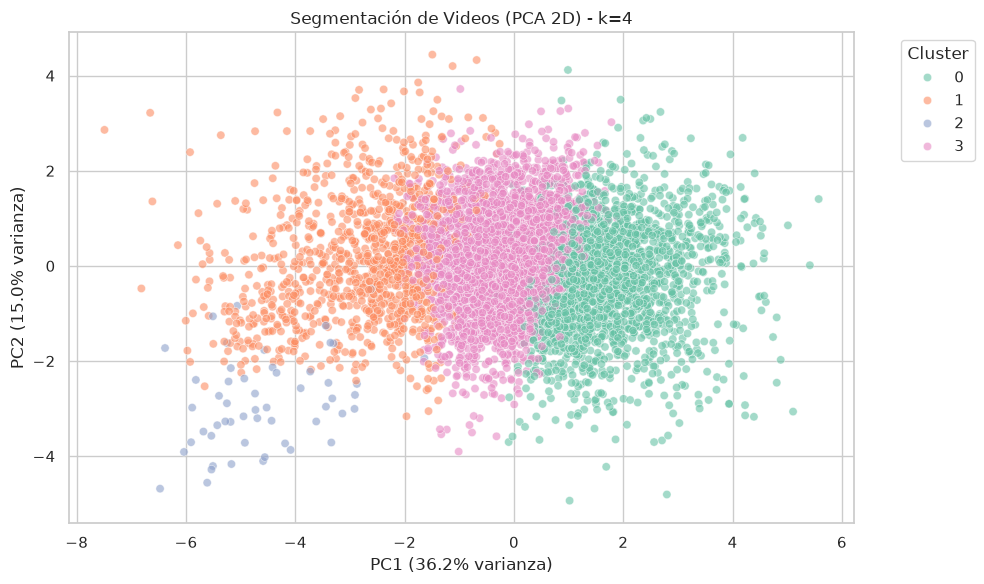

,videos,median_views,median_likes,avg_engagement,avg_like_ratio,avg_days_in_trending,avg_days_to_trending,avg_tags
cluster,,,,,,,,
0,2158,1744781.0,59807.0,4.90,95.69,9.81,1.26,18.98
1,1044,41127.5,377.0,1.58,80.28,3.84,13.93,13.55
2,53,26830.0,82.0,0.60,91.81,3.38,2155.03,10.08
3,3064,401120.5,8147.5,2.99,94.34,5.02,2.32,23.00


In [36]:
# 6. K-Means Final (asumiendo que elegiste k=4, ajústalo según el gráfico)
def plot_kmeans_clusters(data, k):

    kmeans_final = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_data["cluster"] = kmeans_final.fit_predict(scaled_data)

    # 7. Perfil de Clusters
    cluster_profile = data.loc[cluster_data.index].groupby(cluster_data["cluster"]).agg(
        videos=("video_id", "count"),
        median_views=("views", "median"),
        median_likes=("likes", "median"),
        avg_engagement=("engagement_rate", "mean"),
        avg_like_ratio=("like_ratio", "mean"),
        avg_days_in_trending=("days_in_trending", "mean"),
        avg_days_to_trending=("days_to_trending", "mean"),
        avg_tags=("tags_count", "mean")
    ).round(2)

  

    # 8. PCA (Visualización 2D)
    pca = PCA(n_components=2)
    pca_data = pca.fit_transform(scaled_data)

    fig, ax = plt.subplots(figsize=(10, 6))
    sns.scatterplot(
        x=pca_data[:, 0], y=pca_data[:, 1], 
        hue=cluster_data["cluster"], palette="Set2", alpha=0.6, ax=ax
    )
    ax.set_title(f"Segmentación de Videos (PCA 2D) - k={k}")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% varianza)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% varianza)")
    ax.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
    fig.tight_layout()
    plt.show()
    display(cluster_profile)


plot_kmeans_clusters(video_level_for_clustering, k=2)
plot_kmeans_clusters(video_level_for_clustering, k=6)
plot_kmeans_clusters(video_level_for_clustering, k=4)

   

Para identificar perfiles de videos, se aplicó el algoritmo K-Means sobre las variables de rendimiento (log de vistas, likes, comentarios), engagement, like ratio, días en tendencia, velocidad de tracción y uso de tags. Se evaluaron tres escenarios posibles para el número de clústeres:

* `k=2`: Aunque matemáticamente presentó el Silhouette Score más alto (grupos perfectamente separados), dividir la audiencia en solo dos grupos es demasiado genérico y no permite diseñar estrategias de contenido diferenciadas.

* `k=6`: Aunque mostró un pico local en la métrica de Silueta, al proyectar los resultados se evidenció una alta superposición entre los grupos centrales, lo que dificulta su interpretación y explicación ante el negocio.

* `k=4`: Ofrece el mejor balance. La separación visual en el PCA es clara (4 cuadrantes bien definidos) y permite crear 4 arquetipos de audiencia altamente accionables sin caer en la sobre-segmentación.

Perfil de los 4 Arquetipos Identificados:

`Cluster 0 - "Virales Masivos" (2,158 videos):`
* Características: Lideran en vistas (1.7M), tienen el engagement más alto (4.9%) y permanecen casi 10 días en tendencia. Llegan a tendencia en 1.3 días.
* Implicación: Es el perfil ideal para campañas de Reconocimiento (Awareness) y patrocinios. Combina alcance masivo con una audiencia altamente conectada.

`Cluster 3 - "Estándar Optimizado / SEO" (3,064 videos)`:
* Características: Es el grupo más numeroso. Tienen vistas decentes (401k) y su sello distintivo es el uso intensivo de tags (23 en promedio). Llegan a tendencia en 2.3 días.
* Implicación: Demuestra que para competir en el "montón" y llegar a tendencias de forma estándar, la optimización SEO (tags) es un requisito indispensable.

`Cluster 1 - "Bajo Rendimiento / Nicho Frío" (1,044 videos):`
* Características: Vistas muy bajas (41k), engagement bajo (1.6%) y el like ratio más bajo (80.3%). Tardan casi 14 días en llegar a tendencias.
* Implicación: Riesgo para la marca. Son videos con alta tasa de rechazo (muchos dislikes) y tracción lenta. Se deben evitar sus características de producción.

`Cluster 2 - "Resurgimientos Históricos" (53 videos):`
* Características: Videos que tardaron en promedio 2,155 días (casi 6 años) en llegar a tendencias. Tienen pocas vistas (27k) y engagement casi nulo (0.6%).
* Implicación: Son anomalías estadísticas (videos viejos que revivieron por casualidad o resubidas). No representan una estrategia replicable.

Para maximizar el retorno de los sponsors, la marca debe buscar asociarse con videos del Cluster 0 (Virales) o Cluster 3 (SEO). En cuanto a la producción propia, se debe copiar la optimización de tags del Cluster 3 y evitar el estilo de contenido del Cluster 1, que genera rechazo en la audiencia.

## 8. Modelamiento

              precision    recall  f1-score   support

           0       0.35      0.42      0.38       420
           1       0.78      0.72      0.75      1167

    accuracy                           0.64      1587
   macro avg       0.56      0.57      0.57      1587
weighted avg       0.66      0.64      0.65      1587

AUC: 0.606


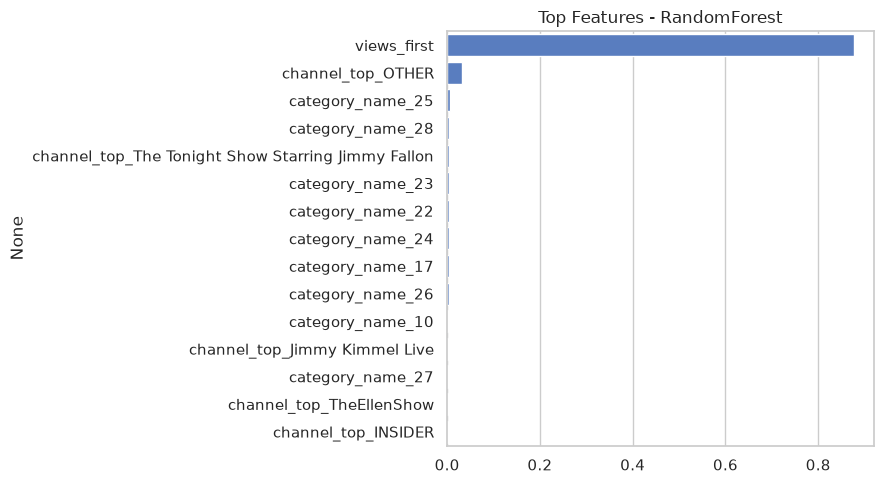

In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix


path_features_modeling = './queries/17_features_modeling.sql'
dfm = read_from_postgres(ROOT_DIR / path_features_modeling)
dfm["fast"] = (dfm["days_to_trending"] <= 2).astype(int)


# One-hot de categoría + canal top-50 (reducir cardinalidad)
top_ch = dfm["channel_title"].value_counts().head(50).index
dfm["channel_top"] = dfm["channel_title"].where(dfm["channel_title"].isin(top_ch), "OTHER")
X = pd.get_dummies(dfm[["category_name", "channel_top",'views_first']],
                   columns=["category_name", "channel_top"], drop_first=True).fillna(0)
y = dfm["fast"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            random_state=42, n_jobs=-1).fit(X_tr, y_tr)

y_pred = rf.predict(X_te)
print(classification_report(y_te, y_pred))
print("AUC:", round(roc_auc_score(y_te, rf.predict_proba(X_te)[:, 1]), 3))

# Importancia de variables
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 5)); sns.barplot(x=imp.values, y=imp.index); plt.title("Top Features - RandomForest")
plt.tight_layout(); plt.show()

--- XGBOOST ---
              precision    recall  f1-score   support

           0       0.35      0.56      0.43       420
           1       0.80      0.63      0.70      1167

    accuracy                           0.61      1587
   macro avg       0.57      0.59      0.56      1587
weighted avg       0.68      0.61      0.63      1587

AUC XGBoost: 0.654


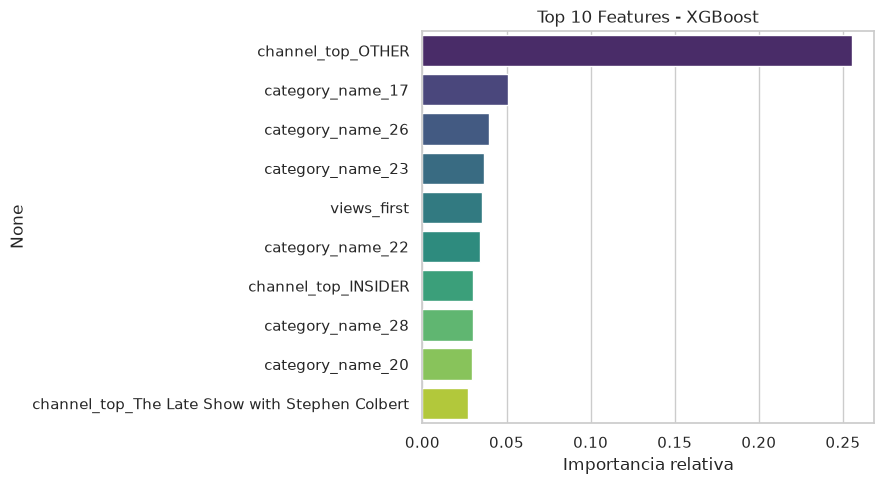

In [44]:
# pip install xgboost (si no lo tienes)
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report

# XGBoost maneja el desbalanceo internamente con scale_pos_weight
# Calculamos el peso (cantidad de clase 0 / cantidad de clase 1)
scale_pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()

xgb = XGBClassifier(
    n_estimators=200, 
    learning_rate=0.05, 
    max_depth=4, 
    scale_pos_weight=scale_pos_weight,
    random_state=42, 
    use_label_encoder=False, 
    eval_metric='logloss'
)

xgb.fit(X_tr, y_tr)
y_pred_xgb = xgb.predict(X_te)

print("--- XGBOOST ---")
print(classification_report(y_te, y_pred_xgb))
print("AUC XGBoost:", round(roc_auc_score(y_te, xgb.predict_proba(X_te)[:, 1]), 3))

# Extraer la importancia de las variables del modelo XGBoost ya entrenado
importancia_xgb = pd.Series(xgb.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

# Graficar
plt.figure(figsize=(9, 5))
sns.barplot(x=importancia_xgb.values, y=importancia_xgb.index, palette="viridis")
plt.title("Top 10 Features - XGBoost")
plt.xlabel("Importancia relativa")
plt.tight_layout()
plt.show()

En las graficas de importancia, Random Forest se sesga hacia views_first (85%), midiendo el sintoma (ya es viral) y no la causa. XGBoost prioriza channel_top_OTHER y categorias, aprendiendo del contexto real del canal.
En los estadisticos, XGBoost supera a Random Forest en AUC (0.654 vs 0.626) y en Recall de la clase lenta (0.56 vs 0.42).
XGBoost tiene menor Accuracy (0.61 vs 0.64) porque es mas conservador, pero logra una mejor Precision (0.80 vs 0.78) al predecir exitos.

Se elige XGBoost porque el modelo no se deja engañar por el trafico inicial. Es mas preciso (80%) al decir que un video sera viral y detecta mejor los videos que fracasan.Para el negocio, esto significa que podemos evitar invertir presupuesto en videos que no tendran traccion, reduciendo el riesgo de falsos positivos.
El techo predictivo (AUC 0.65) demuestra que el algoritmo no es el problema; el dataset necesita variables de retencion (como CTR) para mejorar la prediccion en produccion.


## 9. Conclusiones

### Hallazgos principales

1. El alcance del análisis es acotado. Se estudiaron 6.350 videos que aparecieron en Trending de Estados Unidos entre noviembre de 2017 y junio de 2018, a partir de 40.893 observaciones diarias. Estos datos describen videos que ya llegaron a Trending; no representan todos los videos publicados en YouTube ni permiten estimar la probabilidad de que un video nuevo llegue a esa lista.

2. Presencia y rendimiento no son lo mismo. Entertainment aporta 1.621 videos (25,5 %) y Music 801 (12,6 %); juntas concentran cerca del 38 % de la muestra. Sin embargo, por rendimiento típico, Gaming tiene la mediana de vistas más alta (1,32 millones; 103 videos), mientras que Music combina una mediana alta de vistas (1,10 millones) con la mediana de likes más alta (39.940; 801 videos). Howto & Style registra la mediana de engagement más alta (4,32 %). Las categorías pequeñas requieren cautela: una mediana basada en pocos videos puede cambiar mucho con nuevas observaciones.

3. La distribución de vistas es muy desigual. La mediana es aproximadamente 518 mil vistas, frente a una media de 1,96 millones; el percentil 90 alcanza 3,69 millones y el percentil 99 supera los 25 millones. Un pequeño grupo de éxitos extremos eleva los promedios, por lo que las medianas y percentiles describen mejor el desempeño habitual que la media.

4. La mayoría de los videos aparece en Trending pronto, pero hay casos extremos. La demora mediana observada es de 2 días y el percentil 90 es de 4 días; el máximo de 4.215 días indica una cola excepcional de videos antiguos. Por eso conviene resumir el tiempo con mediana y percentiles, y tratar esos casos antiguos como anomalías antes de convertirlos en una pauta operativa.

5. Los patrones temporales son descriptivos, no causales. Las diferencias por día y mes pueden orientar experimentos, pero esta muestra no demuestra que publicar en una fecha concreta cause más vistas o interacción. Junio está incompleto en el período analizado y las comparaciones estacionales también pueden reflejar cambios en el tipo de contenido, canales o exposición.

6. El clustering ofrece perfiles exploratorios, no segmentos de audiencia. Con k=4 aparecen, entre otros, un grupo de 2.158 videos con mediana de 1,75 millones de vistas y engagement medio de 4,90 %, y otro de 3.064 videos con mediana de 401 mil vistas y engagement de 2,99 %. La elección de k=4 prioriza la interpretación; k=2 obtuvo la silueta más alta. Además, los grupos se construyen con métricas de rendimiento observadas, por lo que describen resultados y no explican qué los causó. Los 53 casos con demoras de años merecen análisis separado.

### Lectura del modelo y límites de decisión

El modelo supervisado del notebook clasifica si un video que ya llegó a Trending lo hizo en dos días o menos; no predice sus vistas o likes ni la probabilidad de entrar a Trending. XGBoost obtiene AUC 0,654 frente a 0,606 de Random Forest, pero su exactitud es 0,61. En la prueba, la clase rápida representa 1.167 de 1.587 casos (73,5 %), así que predecir siempre esa clase daría mayor exactitud. Además, `views_first` se mide cuando el video ya aparece en Trending y no estaría disponible al momento de publicar. El resultado es una exploración con capacidad limitada, no un modelo listo para asignar presupuesto ni recomendar qué video producir.

### Recomendaciones para el negocio

- Definir primero el objetivo de cada iniciativa: alcance (vistas), interacción (likes/comentarios por vista) o rapidez de tracción. Elegir categoría y comparar resultados con esa misma métrica, usando medianas y reportando el número de videos.
- Usar las diferencias por día, mes y categoría para diseñar pruebas controladas o comparaciones con cohortes equivalentes; no convertirlas todavía en reglas de publicación ni atribuir causalidad a los tags, la categoría o el calendario.
- Antes de desplegar un predictor, incluir videos que nunca fueron Trending, medir todos los resultados en un horizonte fijo desde la publicación y validar con una partición temporal. Excluir variables posteriores al momento de predicción, como las vistas de la primera observación en Trending.
- Para estimar ROI o recomendar patrocinios, complementar el dataset con impresiones, CTR, retención, costos, ingresos y conversiones. Sin esas variables, vistas e interacciones no bastan para cuantificar retorno financiero.

El dataset permite identificar categorías con alta presencia y otras con buen rendimiento típico, además de describir perfiles y tiempos de aparición entre los videos que sí fueron tendencia. La evidencia es útil para generar hipótesis y priorizar experimentos, pero no para afirmar qué causa el éxito, pronosticar el desempeño de cualquier publicación ni calcular ROI.